# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import MTARSIDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [16]:
dataset_config = {
    "data_dir": "/home/dragik/data/FAIR_EO/MTARSI/",
    "csv_file": "/home/dragik/data/FAIR_EO/MTARSI/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = MTARSIDataset(dataset_config)

## Show images from the dataset

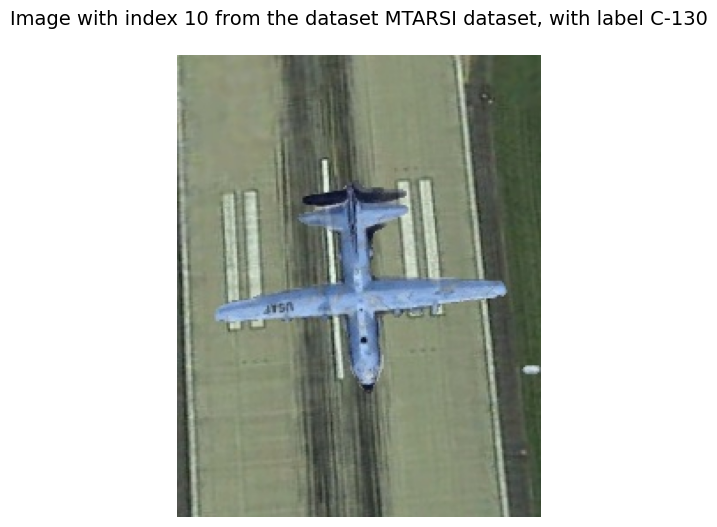

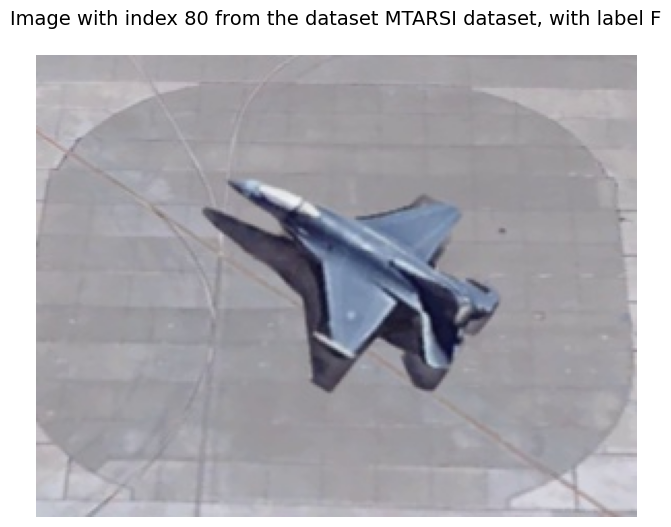

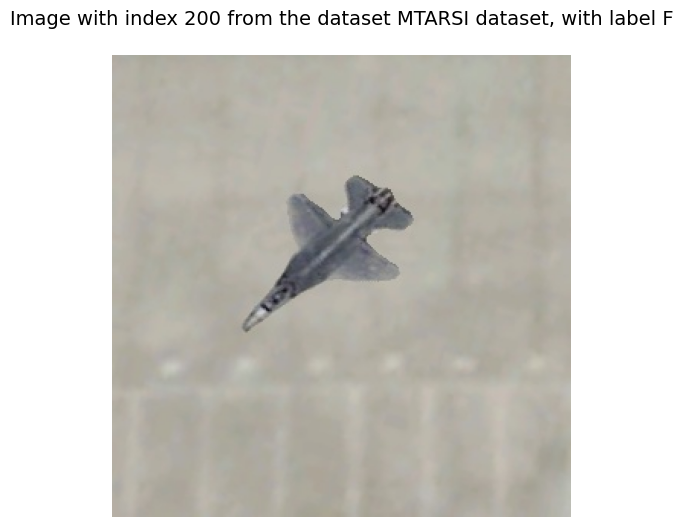

In [17]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

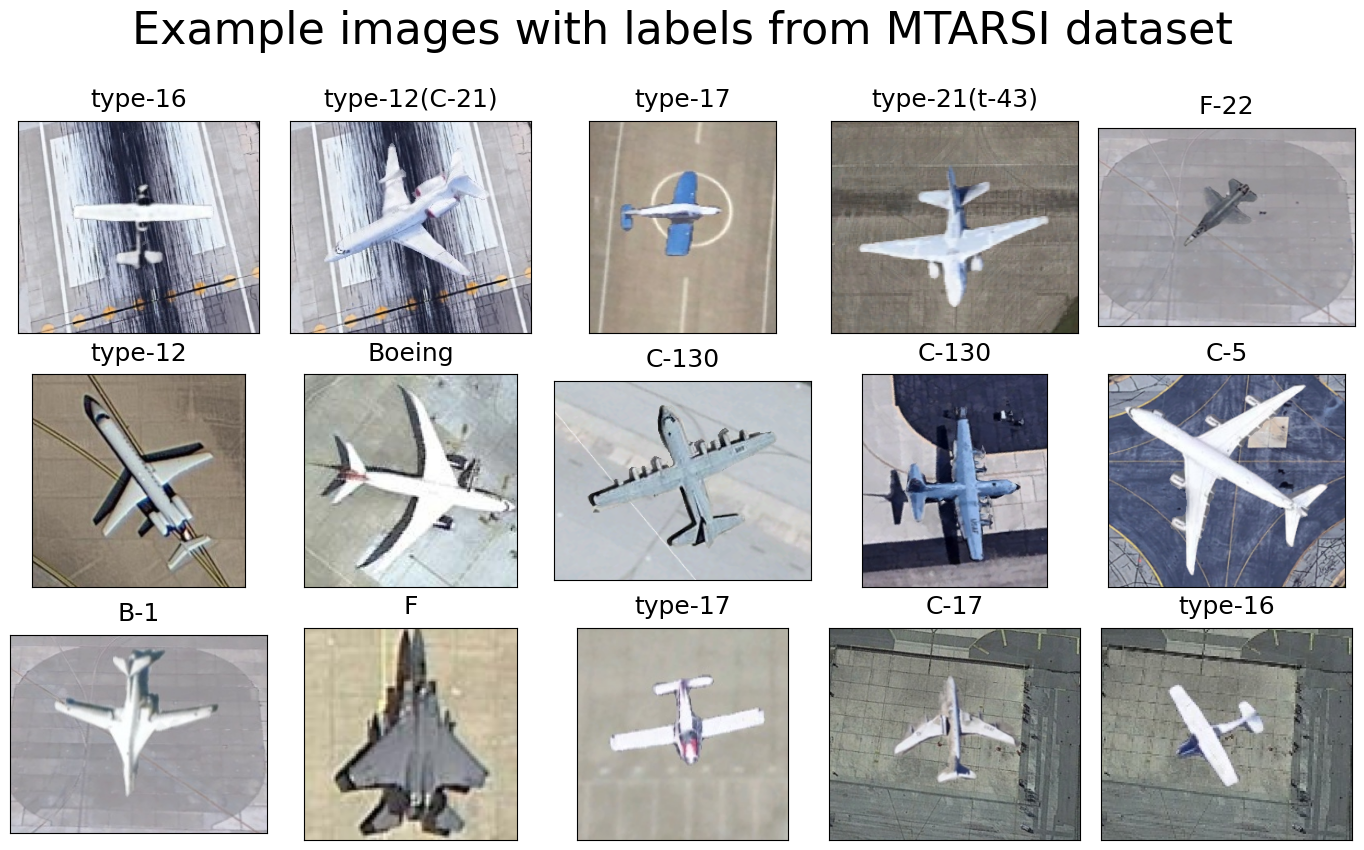

In [8]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [9]:
dataset.show_samples()

,File name,Label
0,C-130/5-476.jpg,C-130
1,type-13(U-2)/13-59.jpg,type-13(U-2)
2,type-21(t-43)/21-56.jpg,type-21(t-43)
3,F-22/10-330.jpg,F-22
4,C-17/7-362.jpg,C-17
5,F-22/10-103.jpg,F-22
6,type-20/20-174.jpg,type-20
7,C-130/image (569).png,C-130
8,C-130/image (567).png,C-130
9,type-15(A-10)/15-32.jpg,type-15(A-10)


In [10]:
dataset.data_distribution_table()

,Label,Count
0,A,491
1,B-1,414
2,B-2,494
3,B-52,441
4,Boeing,478
5,C-130,633
6,C-135,402
7,C-17,386
8,C-5,397
9,E-3,352


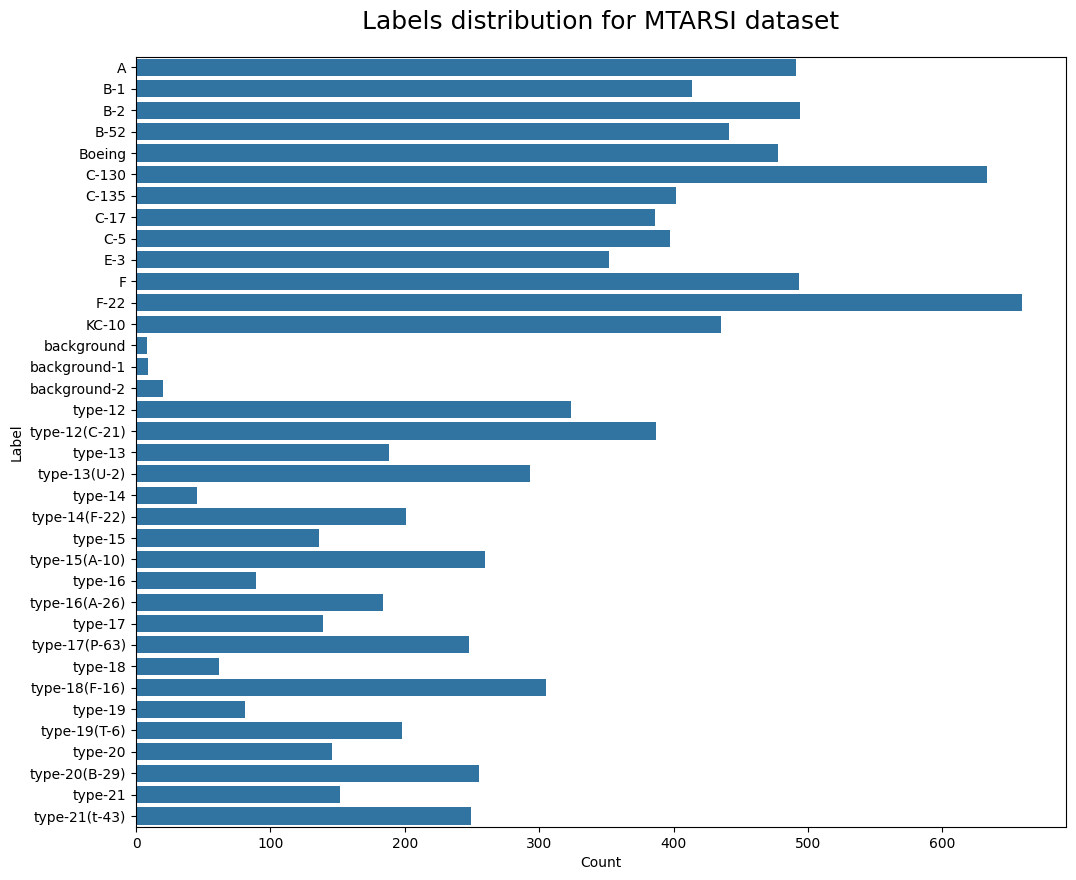

In [11]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [18]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/MTARSI/",
    "csv_file": "/home/dragik/data/FAIR_EO/MTARSI/train.csv",
}

train_dataset = MTARSIDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/MTARSI/",
    "csv_file": "/home/dragik/data/FAIR_EO/MTARSI/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = MTARSIDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(10054, 1256)

## Setup and create the model for training

In [19]:
epochs = 20
model_directory = "/home/dragik/data/FAIR_EO/experiments/MTARSI/"
model_config = {
    "num_classes": 36, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-14 10:55:26,037 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-14 10:55:26,173 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [20]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-14 10:55:26,330 INFO Starting training.
training: 100%|██████████| 315/315 [03:05<00:00,  1.70it/s]
2025-05-14 10:58:32,355 INFO epoch: 1, time: 186, loss:  1.20890
testing on train set: 100%|██████████| 315/315 [01:05<00:00,  4.84it/s]
2025-05-14 10:59:39,339 INFO Accuracy:0.7358265367018102, Precision Micro:0.7358265367018102, Precision Macro:0.6150412799009302, Precision Weighted:0.7169438239881993, Precision per Class:[0.49733333 1.         1.         0.25       0.64738292 0.99772727
 0.48130841 0.94020927 0.95465394 1.         0.97007481 0.99433428
 0.5008881  0.52       0.76701571 0.4894958  0.95794393 0.65796345
 0.71428571 0.70634921 0.6        0.64397906 0.         0.70967742
 0.48148148 0.62834225 0.47752809 0.62285714 0.55319149 0.60356347
 0.36111111 0.48763251 0.38461538 0.         0.         0.54054054], Recall Micro:0.7358265367018102, Recall Macro:0.6148087997929601, Recall Weighted:0.7358265367018102, Recall per Class:[0.75967413 1.         1.         0.0068493

0.35709368274348

## Test the model

In [21]:

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "/home/dragik/data/FAIR_EO/MTARSI/",
    "csv_file": "/home/dragik/data/FAIR_EO/MTARSI/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = MTARSIDataset(test_dataset_config)
model_path = "/home/dragik/data/FAIR_EO/experiments/MTARSI/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-14 12:51:33,708 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/MTARSI/checkpoint.pth.tar
2025-05-14 12:51:35,229 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/MTARSI/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 79/79 [00:14<00:00,  5.51it/s]


[{'Accuracy': 0.697452229299363},
 {'Precision Micro': 0.697452229299363,
  'Precision Macro': 0.6013529873412199,
  'Precision Weighted': 0.7192650694298333,
  'Precision per Class': array([0.30909091, 1.        , 1.        , 0.28571429, 0.71428571,
         1.        , 0.33870968, 1.        , 0.98484848, 0.9787234 ,
         1.        , 1.        , 0.48717949, 0.5       , 0.89285714,
         0.5       , 0.98076923, 0.66      , 0.52      , 0.66666667,
         0.41176471, 0.5862069 , 0.64285714, 1.        , 0.37837838,
         0.85714286, 0.3442623 , 0.625     , 0.35135135, 0.64      ,
         0.22222222, 0.34210526, 0.42857143, 0.        , 0.        ,
         0.        ])},
 {'Recall Micro': 0.697452229299363,
  'Recall Macro': 0.6147545008192064,
  'Recall Weighted': 0.697452229299363,
  'Recall per Class': array([0.29310345, 1.        , 1.        , 0.14285714, 0.85714286,
         1.        , 0.36206897, 1.        , 0.98484848, 0.9787234 ,
         1.        , 1.        , 0.982

## Predictions

2025-05-14 12:52:49,592 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/MTARSI/checkpoint.pth.tar
2025-05-14 12:52:51,181 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/MTARSI/checkpoint.pth.tar at epoch 21


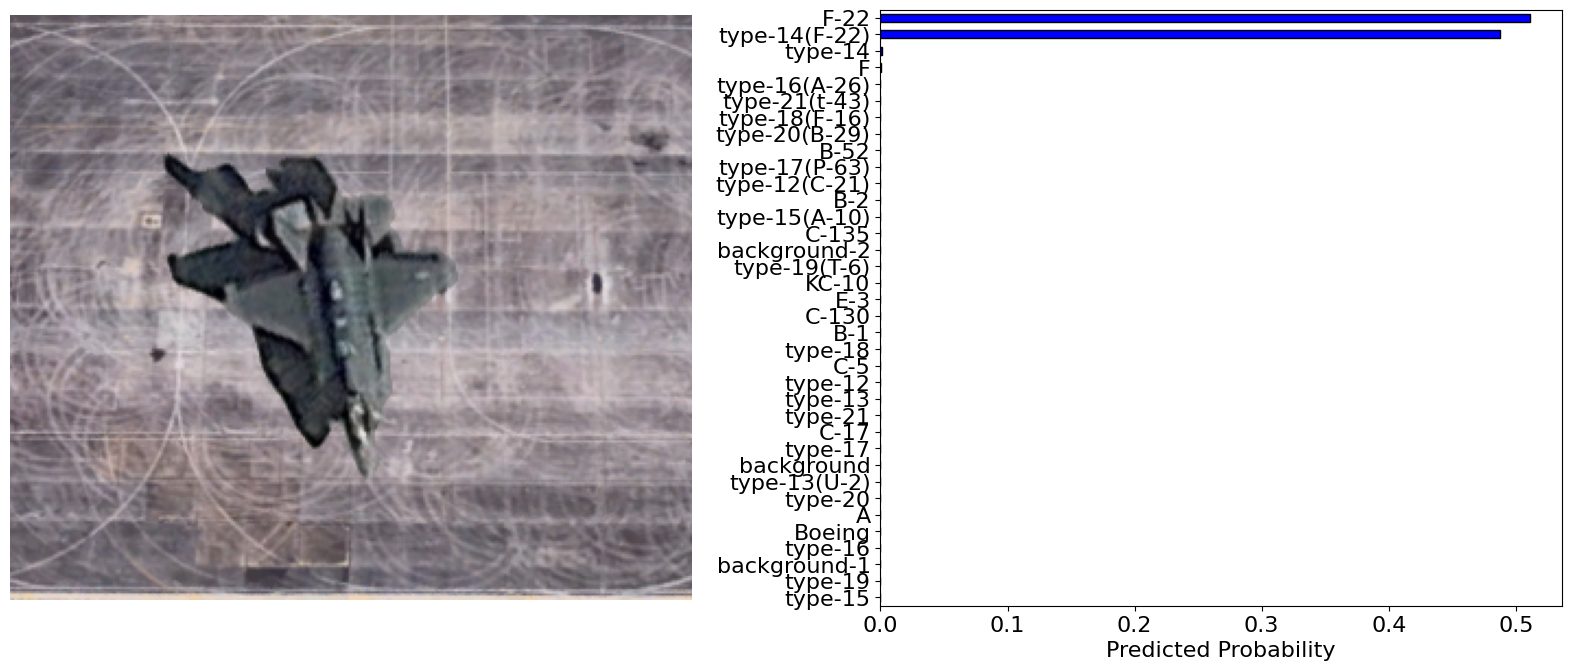

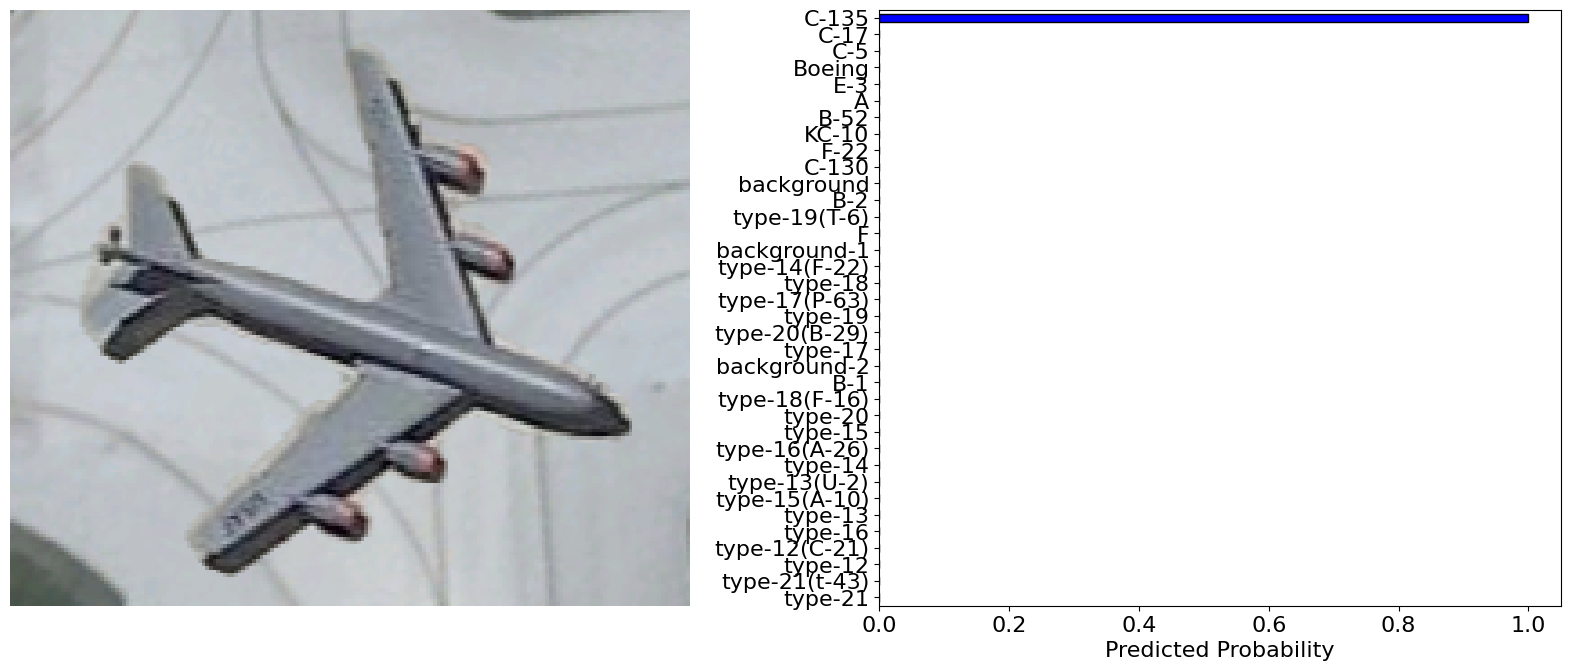

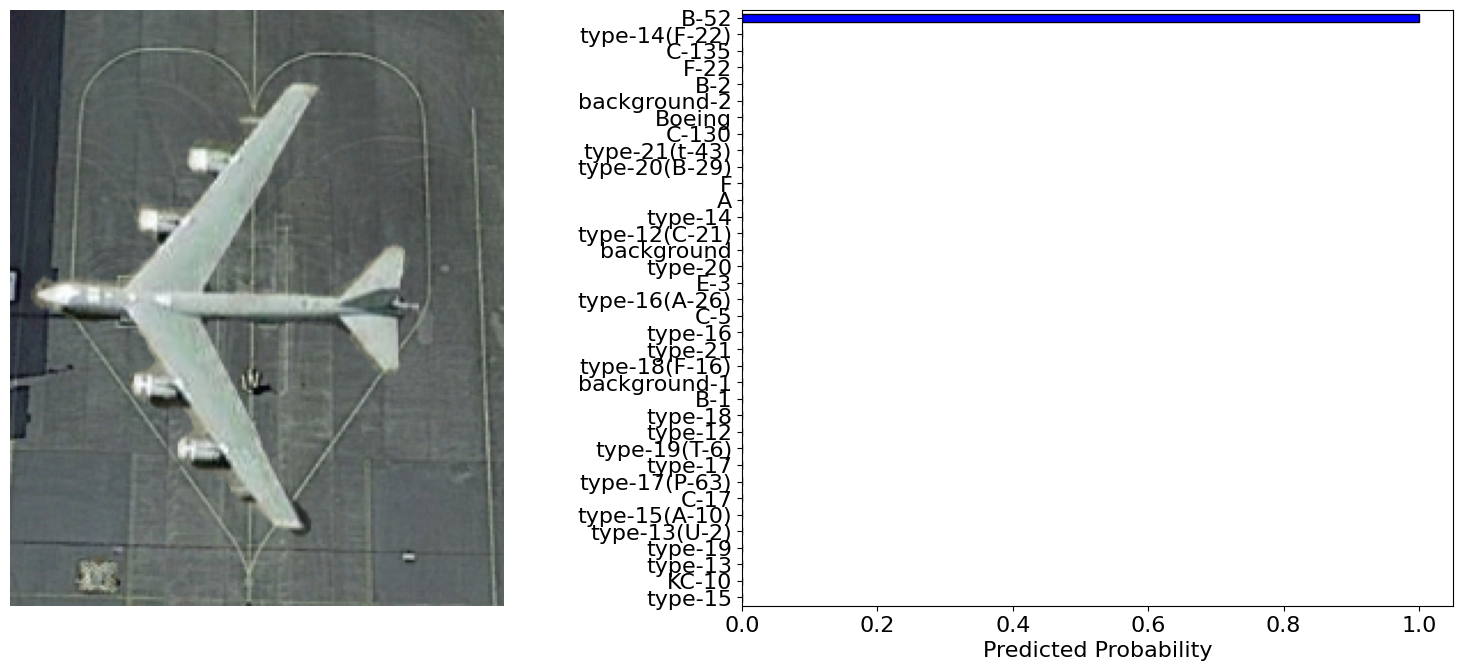

In [23]:
labels = ["A","B-1","B-2","type-20","type-20(B-29)","B-52","Boeing","C-130","C-135","C-17","C-5","E-3","F","type-18",
          "type-18(F-16)","F-22","KC-10","type-15(A-10)","type-16","type-16(A-26)","type-17","type-17(P-63)","type-19",
          "type-19(T-6)","type-21","type-21(t-43)","type-12","type-12(C-21)","type-13","type-13(U-2)","type-14","type-14(F-22)",
          "type-15","background","background-1","background-2"]
transform = ResizeCenterCropToTensor()

model_path = "/home/dragik/data/FAIR_EO/experiments/MTARSI/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('/home/dragik/data/FAIR_EO/MTARSI/F-22/image (59).png')
image = image[:,:,0:3]
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/MTARSI/C-135/image (28).png')
image = image[:,:,0:3]
fig = model.predict_image(image, labels, transform)

image = image_loader('/home/dragik/data/FAIR_EO/MTARSI/B-52/image (207).png')
image = image[:,:,0:3]
fig = model.predict_image(image, labels, transform)